In [2]:
# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

In [3]:
# ============================================================
# STEP 2: LOAD ALL FILES
# ============================================================
customers = pd.read_csv('RAW DATA/customers.csv', encoding= 'unicode_escape')
orders = pd.read_csv('RAW DATA/orders.csv', encoding= 'unicode_escape')  
products = pd.read_csv('RAW DATA/products.csv', encoding= 'unicode_escape')
sessions = pd.read_csv('RAW DATA/sessions.csv', encoding= 'unicode_escape')

In [5]:
# Convert date strings into actual datetime values
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
orders["shipping_date"] = pd.to_datetime(orders["shipping_date"], errors="coerce")
orders["promised_delivery_date"] = pd.to_datetime(orders["promised_delivery_date"], errors="coerce")
orders["actual_delivery_date"] = pd.to_datetime(orders["actual_delivery_date"], errors="coerce")
customers["signup_date"] = pd.to_datetime(customers["signup_date"], errors="coerce")
sessions["timestamp"] = pd.to_datetime(sessions["timestamp"], errors="coerce")

In [6]:
# 1A. Check your event names
print(sessions["event"].value_counts())
print("Unique sessions:", sessions["session_id"].nunique())

event
Home View         10500
Category View      9865
Product View       8053
Add to Cart        4855
Begin Checkout     2355
Purchase           1430
Name: count, dtype: int64
Unique sessions: 10500


Available event columns: ['add to cart', 'begin checkout', 'category view', 'home view', 'product view', 'purchase']

FUNNEL ANALYSIS
         Stage  Sessions  Conversion (%)  Previous Stage Sessions  Drop-off (%)
      Visitors     10500          100.00                      NaN          0.00
  Product View      8053           76.70                  10500.0         23.30
   Add to Cart      3412           32.50                   8053.0         57.63
Begin Checkout       935            8.90                   3412.0         72.60
      Purchase       253            2.41                    935.0         72.94


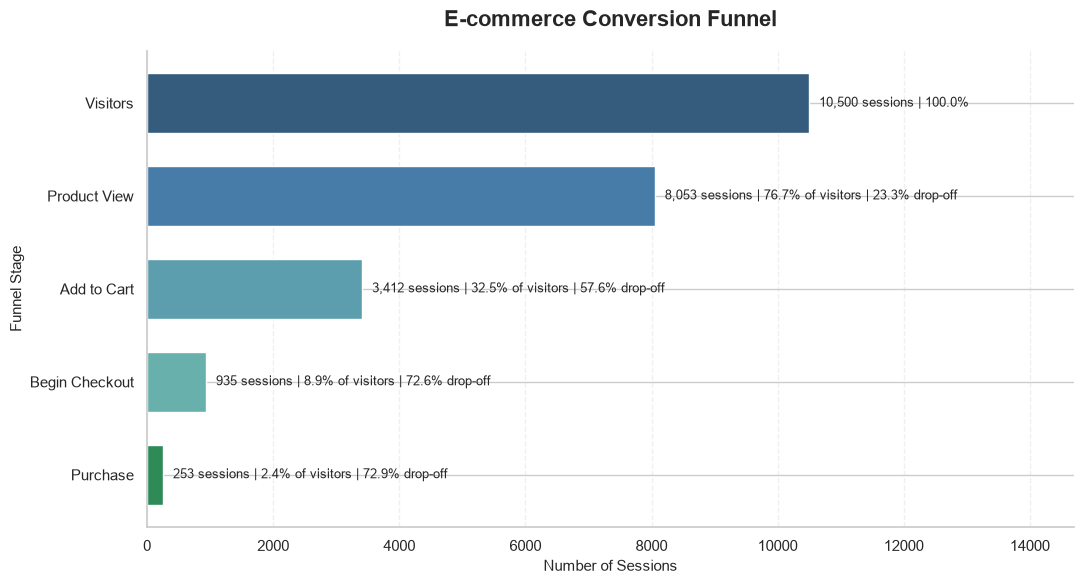

In [13]:
# Q. Stage wise funnel 

# 1. Clean event names
sessions = sessions.copy()
sessions["event_clean"] = (sessions["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# 2. Get the first timestamp for each event in each session
event_times = (
    sessions.groupby(["session_id", "event_clean"])["timestamp"]
    .min()
    .unstack()
)

# 3. Define required events
required_events = [
    "product view",
    "add to cart",
    "begin checkout",
    "purchase"
]

# Check event names
print("Available event columns:", event_times.columns.tolist())

missing_events = [
    event for event in required_events
    if event not in event_times.columns
]

if missing_events:
    print("Missing event names:", missing_events)

else:
    # 4. Extract timestamps
    product_time = event_times["product view"]
    cart_time = event_times["add to cart"]
    checkout_time = event_times["begin checkout"]
    purchase_time = event_times["purchase"]

    # 5. Identify sessions progressing in the correct sequence
    reached_product = product_time.notna()

    reached_cart = (
        reached_product
        & cart_time.notna()
        & (cart_time > product_time)
    )

    reached_checkout = (
        reached_cart
        & checkout_time.notna()
        & (checkout_time > cart_time)
    )

    reached_purchase = (
        reached_checkout
        & purchase_time.notna()
        & (purchase_time > checkout_time)
    )

    # 6. Calculate funnel counts
    funnel = pd.DataFrame({
        "Stage": [
            "Visitors",
            "Product View",
            "Add to Cart",
            "Begin Checkout",
            "Purchase"
        ],
        "Sessions": [
            event_times.shape[0],
            int(reached_product.sum()),
            int(reached_cart.sum()),
            int(reached_checkout.sum()),
            int(reached_purchase.sum())
        ]
    })

    # 7. Calculate conversion and drop-off
    total_visitors = funnel.loc[0, "Sessions"]

    if total_visitors > 0:
        funnel["Conversion (%)"] = (
            funnel["Sessions"] / total_visitors * 100
        ).round(2)
    else:
        funnel["Conversion (%)"] = 0.0

    funnel["Previous Stage Sessions"] = (
        funnel["Sessions"].shift(1)
    )

    funnel["Drop-off (%)"] = 0.0

    previous = funnel["Previous Stage Sessions"]
    valid_previous = previous.notna() & (previous > 0)

    funnel.loc[valid_previous, "Drop-off (%)"] = (
        (
            previous[valid_previous]
            - funnel.loc[valid_previous, "Sessions"]
        )
        / previous[valid_previous]
        * 100
    ).round(2)

    # 8. Print funnel table
    print("\nFUNNEL ANALYSIS")
    print(funnel.to_string(index=False))

    # 9. Create the funnel graph
    fig, ax = plt.subplots(figsize=(11, 6))

    colors = [
        "#355C7D",
        "#477CA8",
        "#5C9EAD",
        "#68B0AB",
        "#2E8B57"
    ]

    bars = ax.barh(
        funnel["Stage"],
        funnel["Sessions"],
        color=colors,
        height=0.65
    )

    # Visitors at the top, purchases at the bottom
    ax.invert_yaxis()

    max_sessions = max(funnel["Sessions"].max(), 1)
    ax.set_xlim(0, max_sessions * 1.40)

    # Add count and conversion labels
    for i, bar in enumerate(bars):
        count = funnel.loc[i, "Sessions"]
        conversion = funnel.loc[i, "Conversion (%)"]
        dropoff = funnel.loc[i, "Drop-off (%)"]

        if i == 0:
            label = f"{count:,} sessions | {conversion:.1f}%"
        else:
            label = (
                f"{count:,} sessions | "
                f"{conversion:.1f}% of visitors | "
                f"{dropoff:.1f}% drop-off"
            )

        ax.text(
            bar.get_width() + max_sessions * 0.015,
            bar.get_y() + bar.get_height() / 2,
            label,
            va="center",
            fontsize=9
        )

    # Chart formatting
    ax.set_title(
        "E-commerce Conversion Funnel",
        fontsize=16,
        fontweight="bold",
        pad=18
    )
    ax.set_xlabel("Number of Sessions", fontsize=11)
    ax.set_ylabel("Funnel Stage", fontsize=11)

    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

                        product_views  add_to_cart  purchases  \
product_category                                                
Skincare                         2102         1280        399   
Beauty & Personal Care           1063          643        181   
Home Essentials                   921          542        148   
Fashion                           867          506        147   
Smartphones                       848          513        164   
Watches                           620          388        117   
Home Appliances                   604          379        110   
Groceries                         437          243         68   
Health & Wellness                 403          247         63   
Baby Care                         188          114         33   

                        purchase_conversion_pct  purchase_dropoff_pct  
product_category                                                       
Skincare                                  18.98                 81.02  
Bea

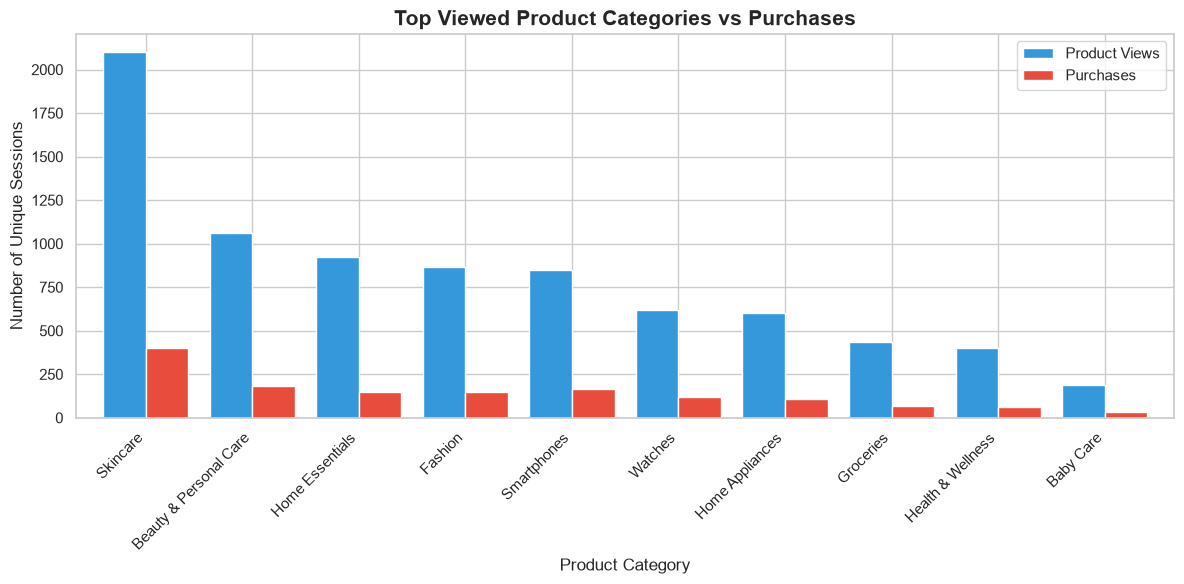

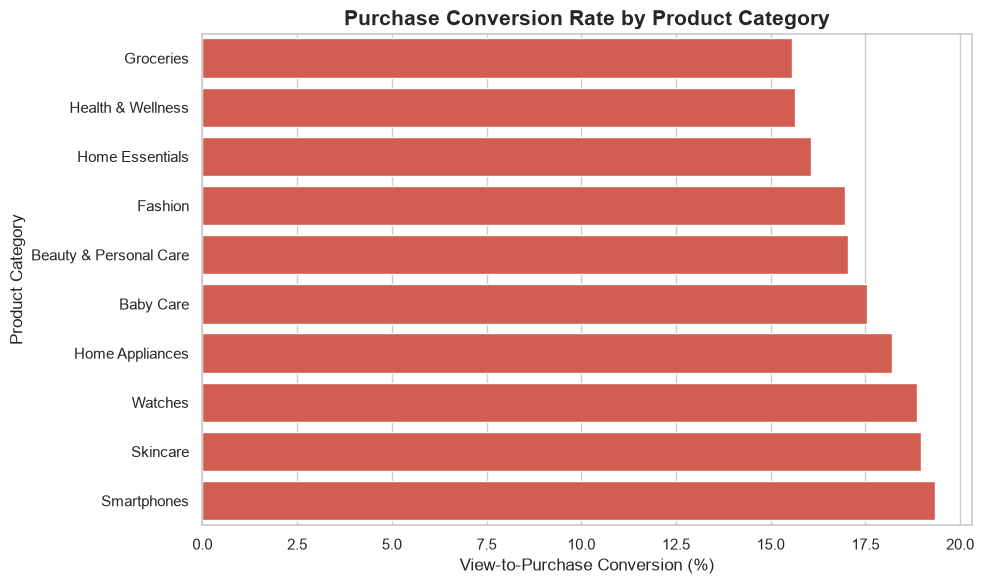

In [8]:
# Q. view vs purchase 

# Standardize event names
sessions["event_clean"] = (
    sessions["event"].astype(str).str.strip().str.lower()
)

sessions["product_category"] = (
    sessions["product_category"].fillna("Unknown")
)

# Count unique sessions viewing each category
views = (
    sessions[sessions["event_clean"] == "product view"]
    .groupby("product_category")["session_id"]
    .nunique()
    .rename("product_views")
)

# Count unique sessions adding each category to cart
carts = (
    sessions[sessions["event_clean"] == "add to cart"]
    .groupby("product_category")["session_id"]
    .nunique()
    .rename("add_to_cart")
)

# Count unique sessions purchasing each category
# Adjust event names here to match your dataset
purchase_events = [
    "purchase",
    "purchase complete",
    "order complete",
    "checkout success"
]

purchases = (
    sessions[sessions["event_clean"].isin(purchase_events)]
    .groupby("product_category")["session_id"]
    .nunique()
    .rename("purchases")
)

# Combine all funnel metrics
category_analysis = pd.concat(
    [views, carts, purchases], axis=1
).fillna(0)

category_analysis = category_analysis.astype(int)

# Calculate conversion and drop-off percentages
category_analysis["purchase_conversion_pct"] = (
    category_analysis["purchases"]
    / category_analysis["product_views"].replace(0, pd.NA)
    * 100
).fillna(0).round(2)

category_analysis["purchase_dropoff_pct"] = (
    100 - category_analysis["purchase_conversion_pct"]
).round(2)

# Sort by highest views and lowest purchases
category_analysis = category_analysis.sort_values(
    ["product_views", "purchases"],
    ascending=[False, True]
)

print(category_analysis)

# Select the top 10 most-viewed categories
top_categories = category_analysis.head(10).copy()

# -------------------------------
# GRAPH 1: Views vs Purchases
# -------------------------------
sns.set_theme(style="whitegrid")

ax = top_categories[
    ["product_views", "purchases"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#3498db", "#e74c3c"],
    width=0.8
)

ax.set_title(
    "Top Viewed Product Categories vs Purchases",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Product Category")
ax.set_ylabel("Number of Unique Sessions")
ax.legend(["Product Views", "Purchases"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# -------------------------------
# GRAPH 2: Purchase Conversion Rate
# -------------------------------
conversion_sorted = top_categories.sort_values(
    "purchase_conversion_pct", ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=conversion_sorted.reset_index(),
    x="purchase_conversion_pct",
    y="product_category",
    color="#e74c3c"
)

plt.title(
    "Purchase Conversion Rate by Product Category",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("View-to-Purchase Conversion (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

Purchase labels found:
purchase_or_not
No     35628
Yes     1430
Name: count, dtype: int64

Marketing Campaign Performance:
                    total_events  total_sessions  purchases  unique_customers  \
marketing_campaign                                                              
Organic                     9113            6351        332              2281   
Push Notification           2946            2629        135              1628   
Search Ads                  5956            4687        239              2137   
Instagram                   6300            4913        241              2147   
Influencer                  3370            2939        136              1710   
Referral                    1898            1760         76              1265   
Email                       3798            3236        137              1801   
Festival Sale               3677            3175        134              1781   

                    purchased_sessions  purchase_conversion_pct  

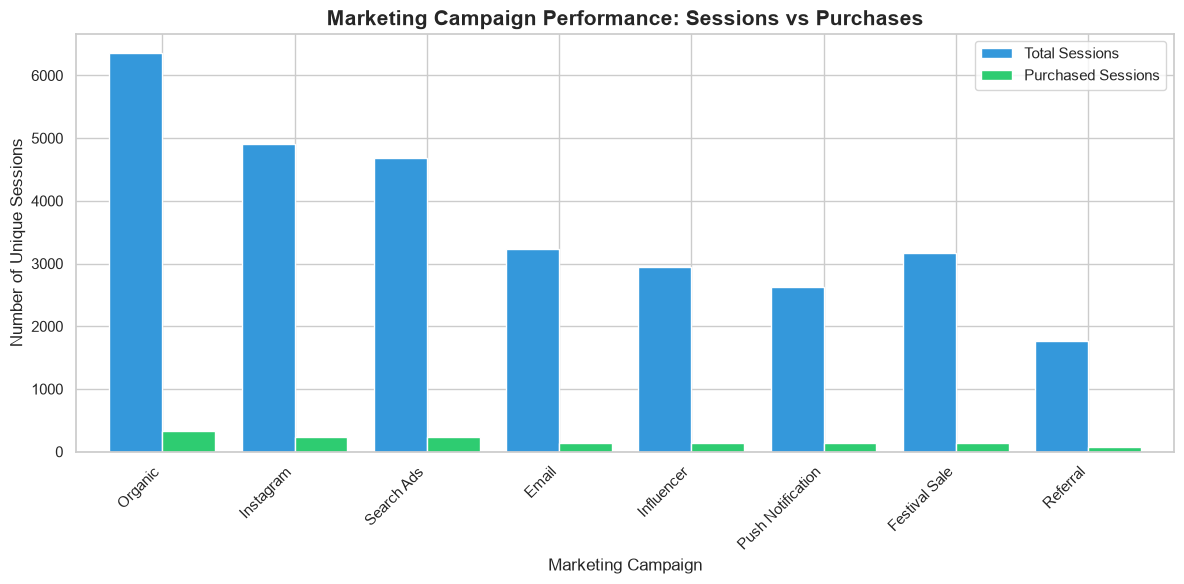

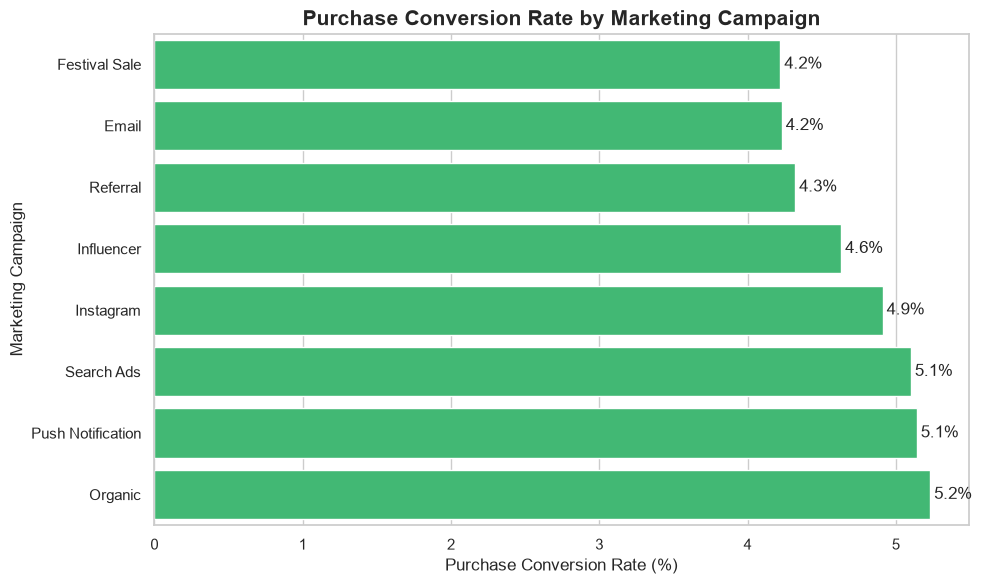

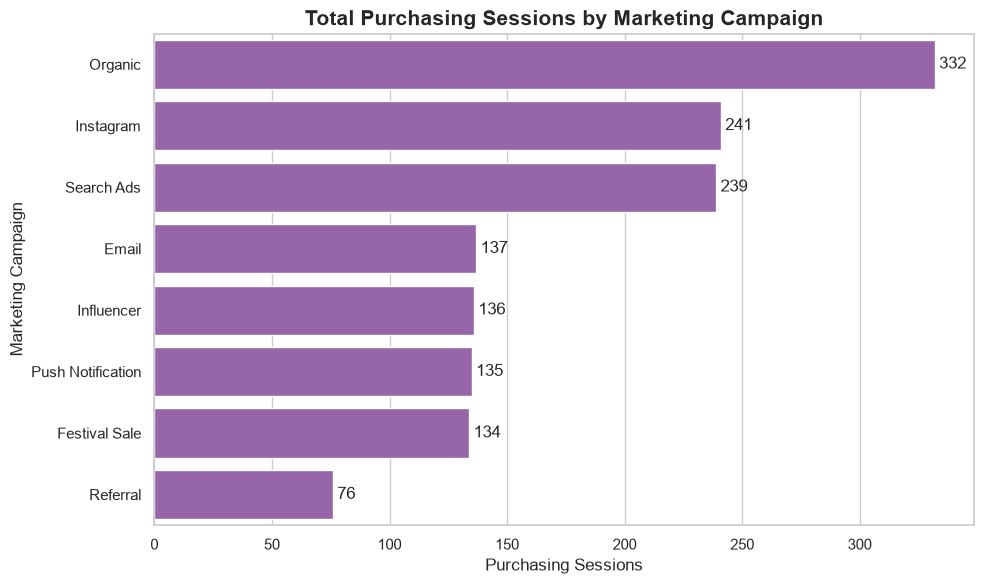


Best campaign by purchase conversion rate:
Campaign: Organic
Purchase conversion: 5.23%
Purchasing sessions: 332
Total sessions: 6351


In [9]:
# Q. Marketing Campaign Performance

# Copy the dataset
df = sessions.copy()

# Clean campaign names
df["marketing_campaign"] = (
    df["marketing_campaign"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Standardize purchase values
df["purchase_clean"] = (
    df["purchase_or_not"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert common purchase labels to True/False
purchase_mapping = {
    "yes": True,
    "true": True,
    "1": True,
    "purchased": True,
    "no": False,
    "false": False,
    "0": False,
    "not purchased": False,
    "not_purchased": False
}

df["is_purchase"] = df["purchase_clean"].map(purchase_mapping)

# Inspect unexpected or missing purchase labels
print("Purchase labels found:")
print(df["purchase_or_not"].value_counts(dropna=False))

# Exclude rows where purchase status is unknown
df_valid = df[df["is_purchase"].notna()].copy()
df_valid["is_purchase"] = df_valid["is_purchase"].astype(bool)

# Campaign performance summary
campaign_performance = (
    df_valid.groupby("marketing_campaign")
    .agg(
        total_events=("event_id", "count"),
        total_sessions=("session_id", "nunique"),
        purchases=("is_purchase", "sum"),
        unique_customers=("customer_id", "nunique")
    )
)

# Count sessions that contain at least one purchase
session_purchase = (
    df_valid.groupby(["marketing_campaign", "session_id"])
    ["is_purchase"]
    .any()
    .reset_index(name="session_purchased")
)

purchased_sessions = (
    session_purchase.groupby("marketing_campaign")
    ["session_purchased"]
    .sum()
)

campaign_performance["purchased_sessions"] = (
    purchased_sessions.reindex(
        campaign_performance.index, fill_value=0
    )
)

# Calculate session-level purchase conversion
campaign_performance["purchase_conversion_pct"] = (
    campaign_performance["purchased_sessions"]
    / campaign_performance["total_sessions"].replace(0, pd.NA)
    * 100
).fillna(0).round(2)

# Purchase rate by customer
campaign_performance["customer_purchase_rate_pct"] = (
    campaign_performance["purchases"]
    / campaign_performance["unique_customers"].replace(0, pd.NA)
    * 100
).fillna(0).round(2)

# Rank campaigns by conversion rate
campaign_performance = campaign_performance.sort_values(
    "purchase_conversion_pct",
    ascending=False
)

print("\nMarketing Campaign Performance:")
print(campaign_performance)

# Set graph style
sns.set_theme(style="whitegrid")

# -------------------------------
# GRAPH 1: Sessions vs Purchases
# -------------------------------
plot_data = campaign_performance.sort_values(
    "purchased_sessions", ascending=False
)

ax = plot_data[
    ["total_sessions", "purchased_sessions"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#3498db", "#2ecc71"],
    width=0.8
)

ax.set_title(
    "Marketing Campaign Performance: Sessions vs Purchases",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Marketing Campaign")
ax.set_ylabel("Number of Unique Sessions")
ax.legend(["Total Sessions", "Purchased Sessions"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# -------------------------------
# GRAPH 2: Purchase Conversion Rate
# -------------------------------
conversion_data = campaign_performance.sort_values(
    "purchase_conversion_pct", ascending=True
).reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=conversion_data,
    x="purchase_conversion_pct",
    y="marketing_campaign",
    color="#2ecc71"
)

ax.set_title(
    "Purchase Conversion Rate by Marketing Campaign",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Purchase Conversion Rate (%)")
ax.set_ylabel("Marketing Campaign")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# -------------------------------
# GRAPH 3: Campaign Purchase Volume
# -------------------------------
volume_data = campaign_performance.sort_values(
    "purchased_sessions", ascending=False
).reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=volume_data,
    x="purchased_sessions",
    y="marketing_campaign",
    color="#9b59b6"
)

ax.set_title(
    "Total Purchasing Sessions by Marketing Campaign",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Purchasing Sessions")
ax.set_ylabel("Marketing Campaign")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# -------------------------------
# BEST CAMPAIGN
# -------------------------------
if not campaign_performance.empty:
    best_campaign = campaign_performance.iloc[0]

    print("\nBest campaign by purchase conversion rate:")
    print("Campaign:", campaign_performance.index[0])
    print(
        "Purchase conversion:",
        f"{best_campaign['purchase_conversion_pct']:.2f}%"
    )
    print(
        "Purchasing sessions:",
        int(best_campaign["purchased_sessions"])
    )
    print(
        "Total sessions:",
        int(best_campaign["total_sessions"])
    )